# Supervised Learning: Regression (I)
## Praktik terbimbing dengan housing.csv

**Untuk peserta yang belum pernah coding.** Kita mulai dari membaca tabel,
membuat regresi sederhana, lalu menyusun regresi berganda dan menilai prediksinya.
Alurnya mengikuti materi slide: supervised learning, regresi linear, modelling,
multikolinearitas, evaluasi, serta underfitting dan overfitting.

**Cara mulai di komputer:** buka notebook ini dan pertahankan susunan folder
proyek. Data dibaca otomatis dari `data/housing.csv`.
**Di Google Colab:** unggah notebook ini, lalu unggah `housing.csv` dari folder
`data/` atau `data_tutorial.zip` dari folder `paket/` melalui panel **Files**.
Jalankan sel berurutan dengan **Shift + Enter** atau **Run all**. Tidak perlu
menyambungkan Google Drive atau menuliskan lokasi folder komputer tertentu.

Hasil eksekusi disimpan di notebook ini. Jika ingin mencoba sendiri dari awal,
mulai ulang kernel/runtime dan jalankan semua sel berurutan.



### Peta materi dan tujuan belajar

| Bagian notebook | Acuan slide | Setelah praktik, peserta dapat... |
|---|---|---|
| 1. Konsep dan persamaan garis | 4-15 | Membedakan fitur/target, slope/intersep, dan jenis regresi. |
| 2-4. Data, pembagian, dan pembersihan | 17-20 | Membaca CSV, membagi 80:20, dan mengisi data kosong dengan benar. |
| 5. Regresi sederhana | 18-21 | Memakai RM untuk memprediksi MEDV dan membaca koefisien. |
| 6-8. VIF, korelasi, dan regresi berganda | 22-25 | Menilai multikolinearitas dan membandingkan model dengan/tanpa RAD. |
| 9. Evaluasi | 26-28 | Membaca RMSE, R², serta grafik aktual dan prediksi. |
| 10. Prediksi baru | 5-6 | Memakai model untuk dua profil baru, termasuk data kosong. |
| 11. Pipeline | Pengayaan dari notebook awal | Menggabungkan langkah yang sudah dipahami. |
| 12. Underfitting/overfitting | 29-30 | Membaca perbedaan hasil train dan validasi. |
| 13. Latihan dan ringkasan | Penutup | Menjelaskan hasil dengan satuan dan batasan yang benar. |

Untuk pertemuan pertama, utamakan bagian 1-10. Bagian 11-12 adalah pendalaman.
Semua sel kode sudah lengkap dan dapat dijalankan; latihan tambahan ada di akhir.

### Cara membaca kode

| Kode/simbol | Arti |
|---|---|
| `# ...` | Catatan yang tidak dihitung oleh Python. |
| `data = ...` | Simpan hasil dengan nama `data`. |
| `data["RM"]` | Ambil satu kolom. `data[["RM"]]` mempertahankan bentuk tabel. |
| `data.head()` | Tampilkan lima baris pertama. |
| `model.fit(X, y)` | Pelajari hubungan fitur dan target dari data train. |
| `model.predict(X_baru)` | Hitung prediksi untuk fitur yang diberikan. |

Nama kolom harus sama persis, termasuk huruf besar. Desimal di kode memakai titik.



## 1. Konsep yang dipakai

Pada **supervised learning**, data latihan sudah mempunyai target atau jawaban.
Pada kasus ini, fitur adalah karakteristik wilayah/perumahan dan target adalah
`MEDV`. **Regresi** memprediksi angka kontinu; **klasifikasi** memprediksi kategori.
Pada unsupervised learning, target tidak disediakan, misalnya pengelompokan wilayah.

| Model pada slide | Kegunaan |
|---|---|
| Regresi linear sederhana | Satu fitur untuk memprediksi target kontinu. |
| Regresi linear berganda | Beberapa fitur untuk memprediksi target kontinu. |
| Regresi polinomial | Menambahkan pangkat fitur untuk hubungan melengkung. |
| Ridge dan Lasso | Memberi penalti koefisien; berguna saat perlu regularisasi. |
| Logistic regression | Walaupun namanya regression, umumnya dipakai untuk klasifikasi. |

Fokus praktik ini adalah regresi linear. Polinomial dipakai kembali di bagian 12.

Persamaan sederhana: $\hat{y} = b_0 + b_1 x$. Intersep $b_0$ adalah nilai prediksi
saat x nol; slope $b_1$ adalah perubahan prediksi untuk tambahan satu unit x.
Pada model berganda, tambahkan $b_2 x_2$, $b_3 x_3$, dan seterusnya.
OLS memilih koefisien yang meminimalkan jumlah kuadrat error pada data train.

### Contoh persamaan garis dari slide: tarif taksi

Tarif awal kedua taksi Rp5.000. Slope taksi standar Rp4.000/km, sedangkan
taksi premium Rp7.500/km. Contoh ini membantu membaca persamaan sebelum memakai model.



### Persiapan lokasi data

Jalankan sel ini apa adanya. Sel ini menemukan data pada susunan folder
proyek atau membuka paket data yang Anda unggah di Colab.



In [1]:
import os
import zipfile
from pathlib import Path

# Di komputer sendiri, temukan folder data dari lokasi notebook ini.
# Di Colab, folder kerja tetap memakai lokasi unggahan Anda.
if not Path("data").is_dir() and Path("../../data").is_dir():
    os.chdir("../..")

if Path("data_tutorial.zip").exists() and not Path("data/housing.csv").exists():
    with zipfile.ZipFile("data_tutorial.zip") as paket:
        paket.extractall(".")



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Pengaturan tampilan; cukup jalankan apa adanya.
pd.set_option("display.max_columns", 14)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110



In [3]:
jarak = pd.DataFrame({"km": [0, 1, 2, 3]})
jarak["taksi_standar"] = 5000 + 4000 * jarak["km"]
jarak["taksi_premium"] = 5000 + 7500 * jarak["km"]
jarak



,km,taksi_standar,taksi_premium
0,0,5000,5000
1,1,9000,12500
2,2,13000,20000
3,3,17000,27500


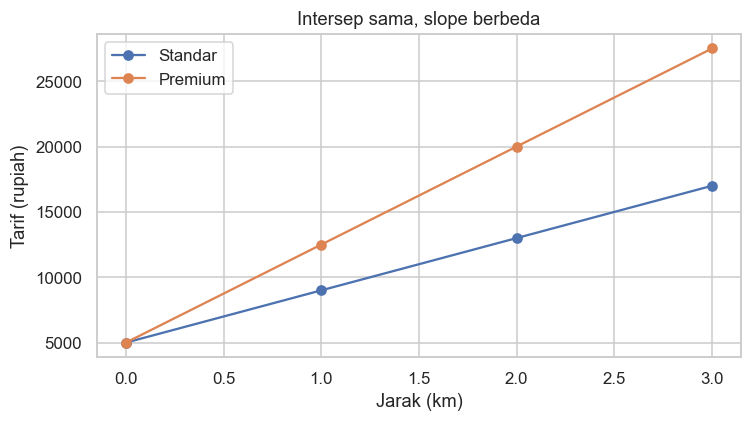

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(jarak["km"], jarak["taksi_standar"], marker="o", label="Standar")
plt.plot(jarak["km"], jarak["taksi_premium"], marker="o", label="Premium")
plt.xlabel("Jarak (km)")
plt.ylabel("Tarif (rupiah)")
plt.title("Intersep sama, slope berbeda")
plt.legend()
plt.tight_layout()
plt.show()



## 2. Baca dan kenali data

Kita memakai **berkas lokal yang diberikan**, `housing.csv`, tanpa mengunduh data.
Satu baris mewakili karakteristik suatu wilayah dalam dataset historis Boston Housing,
bukan satu rumah tertentu di Indonesia. `MEDV` adalah nilai median rumah yang dihuni
pemiliknya, dalam **ribuan dolar AS pada data historis**. MEDV = 24 berarti sekitar
US$24.000 pada konteks data tersebut, bukan Rp24 juta atau harga saat ini.

| Kolom | Arti ringkas |
|---|---|
| CRIM | Tingkat kejahatan per kapita wilayah. |
| ZN | Proporsi lahan hunian dengan ukuran kavling lebih dari 25.000 kaki persegi. |
| INDUS | Proporsi lahan bisnis nonritel. |
| CHAS | Dummy berbatasan dengan Sungai Charles: 1 ya, 0 tidak. |
| NOX | Konsentrasi nitrogen oksida, bagian per 10 juta. |
| RM | Rata-rata jumlah kamar per hunian. |
| AGE | Proporsi hunian milik penghuni yang dibangun sebelum 1940. |
| DIS | Jarak tertimbang ke lima pusat pekerjaan. |
| RAD | Indeks akses ke jalan raya radial. |
| TAX | Tarif pajak properti per US$10.000. |
| PTRATIO | Rasio murid terhadap guru. |
| BLACK | Variabel historis B: transformasi komposisi ras penduduk. |
| LSTAT | Persentase penduduk berstatus sosial ekonomi rendah menurut definisi historis dataset. |
| MEDV | Target: median nilai rumah dalam ribuan dolar AS. |

**Catatan dataset untuk dibahas di kelas.** Boston Housing mempunyai persoalan etis,
terutama rekayasa variabel B/BLACK berdasarkan asumsi tentang ras. Kita mempertahankan
kolom berkas untuk mereproduksi latihan dan membahas batasannya. Dataset ini bukan
dasar untuk membuat keputusan harga atau menilai kelompok penduduk; menghapus satu
kolom saja juga belum menjamin hilangnya bias. Sebagian nilai MEDV berhenti pada 50,
sehingga pembacaan prediksi di sekitar batas tersebut perlu hati-hati.
Rujukan definisi dan catatan ini ada di akhir notebook.



In [5]:
# CSV tunggal yang diunggah ke Colab dapat dibaca dari folder unggahan.
lokasi_data = "data/housing.csv"
if not Path(lokasi_data).exists() and Path("housing.csv").exists():
    lokasi_data = "housing.csv"

data = pd.read_csv(lokasi_data)
print("Jumlah baris:", data.shape[0])
print("Jumlah kolom:", data.shape[1])
data.head()



Jumlah baris: 506
Jumlah kolom: 14


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,BLACK,LSTAT,MEDV
0,0.006,18.0,2.31,0,0.538,6.575,65.2,4.090,1,296,15.3,396.90,4.98,24.0
1,0.027,0.0,7.07,0,0.469,6.421,78.9,4.967,2,242,17.8,396.90,9.14,21.6
2,0.027,0.0,7.07,0,0.469,7.185,61.1,4.967,2,242,17.8,392.83,4.03,34.7
3,0.032,0.0,2.18,0,0.458,6.998,45.8,6.062,3,222,18.7,394.63,2.94,33.4
4,0.069,0.0,2.18,0,0.458,7.147,54.2,6.062,3,222,18.7,396.90,5.33,36.2


`info()` menunjukkan jenis kolom dan banyaknya nilai yang terisi. `describe()`
merangkum rata-rata, sebaran, dan rentang. Pemeriksaan data dilakukan sebelum modelling.



In [6]:
data.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  BLACK    506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [7]:
data.describe().round(2)



,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,BLACK,LSTAT,MEDV
count,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00
mean,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65,22.53
std,8.60,23.32,6.86,0.25,0.12,0.70,28.15,2.11,8.71,168.54,2.16,91.29,7.14,9.20
min,0.01,0.00,0.46,0.00,0.38,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
25%,0.08,0.00,5.19,0.00,0.45,5.89,45.02,2.10,4.00,279.00,17.40,375.38,6.95,17.02
50%,0.26,0.00,9.69,0.00,0.54,6.21,77.50,3.21,5.00,330.00,19.05,391.44,11.36,21.20
75%,3.68,12.50,18.10,0.00,0.62,6.62,94.07,5.19,24.00,666.00,20.20,396.22,16.96,25.00
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


In [8]:
pemeriksaan = pd.DataFrame({"jumlah_kosong": data.isna().sum()})
pemeriksaan["persen_kosong"] = 100 * pemeriksaan["jumlah_kosong"] / len(data)
print("Baris duplikat:", data.duplicated().sum())
print("Target MEDV kosong:", data["MEDV"].isna().sum())
pemeriksaan



Baris duplikat: 0
Target MEDV kosong: 0


,jumlah_kosong,persen_kosong
CRIM,0,0.0
ZN,0,0.0
INDUS,0,0.0
CHAS,0,0.0
NOX,0,0.0
RM,0,0.0
AGE,0,0.0
DIS,0,0.0
RAD,0,0.0
TAX,0,0.0


Pada berkas yang diuji, terdapat 506 baris, 14 kolom, tanpa nilai kosong atau
duplikat. Kita tetap memperagakan imputasi karena data baru dapat belum lengkap.
Jangan mengarang nilai target yang kosong untuk pelatihan. Jika data diganti,
periksa kembali hasil pemeriksaan ini sebelum melanjutkan.



## 3. Pisahkan fitur, target, dan data train-test

`X` berisi 13 fitur; `y` berisi MEDV. **MEDV tidak boleh masuk ke X**, karena itulah
jawaban yang hendak diprediksi. Data dibagi **80% train, 20% test** seperti slide.
`random_state=42` membuat pembagian bisa diulang dengan hasil yang sama.

Data train dipakai untuk mempelajari pola, median imputasi, serta korelasi/VIF.
Data test disimpan untuk evaluasi setelah model ditentukan. Jangan mengubah model
berulang kali untuk mengejar nilai test yang lebih bagus; pemilihan model memerlukan
validasi di dalam data train. Contohnya ada di bagian 12.



In [9]:
X = data.drop(columns=["MEDV"])
y = data["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Data train:", len(X_train), "baris")
print("Data test :", len(X_test), "baris")
print("Jumlah fitur:", X_train.shape[1])
X_train.head()



Data train: 404 baris
Data test : 102 baris
Jumlah fitur: 13


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,BLACK,LSTAT
477,15.023,0.0,18.10,0,0.614,5.304,97.3,2.101,24,666,20.2,349.48,24.91
15,0.627,0.0,8.14,0,0.538,5.834,56.5,4.499,4,307,21.0,395.62,8.47
332,0.035,35.0,6.06,0,0.438,6.031,23.3,6.641,1,304,16.9,362.25,7.83
423,7.050,0.0,18.10,0,0.614,6.103,85.1,2.022,24,666,20.2,2.52,23.29
19,0.726,0.0,8.14,0,0.538,5.727,69.5,3.796,4,307,21.0,390.95,11.28


## 4. Tangani data kosong tanpa membocorkan informasi test

Median dihitung **hanya dari train** menggunakan `fit_transform()`. Data test
memakai median yang sama lewat `transform()`. Ini tetap perlu dijaga walaupun
CSV saat ini lengkap. Menghitung median dari gabungan train dan test akan
memakai informasi yang seharusnya belum diketahui saat melatih model.

Hasil imputer berupa kumpulan angka. Kita ubah kembali menjadi tabel dengan
nama kolom **dan indeks baris yang sama**. Indeks adalah penanda observasi;
menjaganya memastikan fitur dan MEDV tetap berpasangan saat digabung.



In [10]:
pengisi_kosong = SimpleImputer(strategy="median")

angka_train = pengisi_kosong.fit_transform(X_train)
angka_test = pengisi_kosong.transform(X_test)

X_train_bersih = pd.DataFrame(angka_train, columns=X_train.columns, index=X_train.index)
X_test_bersih = pd.DataFrame(angka_test, columns=X_test.columns, index=X_test.index)

print("Nilai kosong train:", X_train_bersih.isna().sum().sum())
print("Nilai kosong test :", X_test_bersih.isna().sum().sum())
print("Indeks fitur dan target train sama:", X_train_bersih.index.equals(y_train.index))
X_train_bersih.head()



Nilai kosong train: 0
Nilai kosong test : 0
Indeks fitur dan target train sama: True


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,BLACK,LSTAT
477,15.023,0.0,18.10,0.0,0.614,5.304,97.3,2.101,24.0,666.0,20.2,349.48,24.91
15,0.627,0.0,8.14,0.0,0.538,5.834,56.5,4.499,4.0,307.0,21.0,395.62,8.47
332,0.035,35.0,6.06,0.0,0.438,6.031,23.3,6.641,1.0,304.0,16.9,362.25,7.83
423,7.050,0.0,18.10,0.0,0.614,6.103,85.1,2.022,24.0,666.0,20.2,2.52,23.29
19,0.726,0.0,8.14,0.0,0.538,5.727,69.5,3.796,4.0,307.0,21.0,390.95,11.28


## 5. Regresi sederhana: satu fitur RM

Pertanyaan: apakah rata-rata jumlah kamar dapat membantu memprediksi MEDV?
Kita memakai satu fitur, `RM`, dengan target yang sama. Grafik memakai data train.
Pada slide contohnya suhu dan curah hujan; di sini langkah yang sama diterapkan
pada data Housing sehingga seluruh praktik memakai CSV yang Anda miliki.



In [11]:
X_train_sederhana = X_train_bersih[["RM"]]
X_test_sederhana = X_test_bersih[["RM"]]

model_sederhana = LinearRegression()
model_sederhana.fit(X_train_sederhana, y_train)

intersep = model_sederhana.intercept_
slope_rm = model_sederhana.coef_[0]
print("Intersep:", round(intersep, 3))
print("Koefisien RM:", round(slope_rm, 3))
print("Persamaan MEDV =", round(intersep, 3), "+", round(slope_rm, 3), "x RM")



Intersep:

 -36.246
Koefisien RM: 9.348
Persamaan MEDV = -36.246 + 9.348 x RM


Koefisien RM dibaca dalam **ribuan dolar AS per tambahan satu kamar rata-rata**.
Ini hubungan prediktif pada data, bukan bukti bahwa menambah kamar menyebabkan
harga naik sebesar itu. Intersep saat RM = 0 berada di luar konteks rumah pada
data ini sehingga tidak ditafsirkan sebagai harga rumah yang realistis.



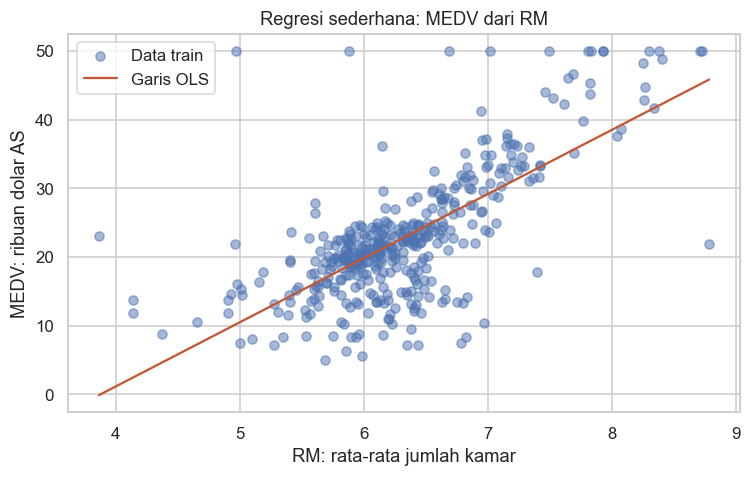

In [12]:
garis = pd.DataFrame({"RM": [X_train_bersih["RM"].min(), X_train_bersih["RM"].max()]})
garis["prediksi"] = model_sederhana.predict(garis)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_train_bersih["RM"], y_train, alpha=0.5, label="Data train")
plt.plot(garis["RM"], garis["prediksi"], color="#C15937", label="Garis OLS")
plt.xlabel("RM: rata-rata jumlah kamar")
plt.ylabel("MEDV: ribuan dolar AS")
plt.title("Regresi sederhana: MEDV dari RM")
plt.legend()
plt.tight_layout()
plt.show()



In [13]:
contoh_rm = pd.DataFrame({"RM": [6.0, 7.0]})
contoh_rm["prediksi_MEDV"] = model_sederhana.predict(contoh_rm)
contoh_rm



,RM,prediksi_MEDV
0,6.0,19.843
1,7.0,29.192


## 6. Sebelum regresi berganda: korelasi dan VIF

**Multikolinearitas** berarti fitur saling berhubungan kuat. Koefisien dapat menjadi
tidak stabil dan sulit ditafsirkan, walaupun prediksi belum tentu buruk.
VIF melihat hubungan satu fitur dengan kumpulan fitur lainnya; korelasi pasangan
melengkapi pemeriksaan tersebut. Angka VIF sekitar 1 rendah; angka 5-10 patut
diperiksa, dan di atas 10 sering dipakai sebagai tanda masalah besar. Ini pedoman,
bukan batas otomatis untuk membuang variabel.

### 6.1 Korelasi pada data train

Salin tabel fitur bersih, lalu tambahkan MEDV berdasarkan indeks barisnya.
Target dimasukkan **hanya untuk analisis korelasi**, bukan sebagai fitur prediksi.



In [14]:
data_train = X_train_bersih.copy()
data_train["MEDV"] = y_train
korelasi = data_train.corr()

print("Baris data train untuk korelasi:", len(data_train))
print("Nilai kosong setelah penggabungan:", data_train.isna().sum().sum())
korelasi.loc[["TAX", "RAD"], ["TAX", "RAD", "MEDV"]].round(3)



Baris data train untuk korelasi: 404
Nilai kosong setelah penggabungan: 0


,TAX,RAD,MEDV
TAX,1.000,0.913,-0.460
RAD,0.913,1.000,-0.387


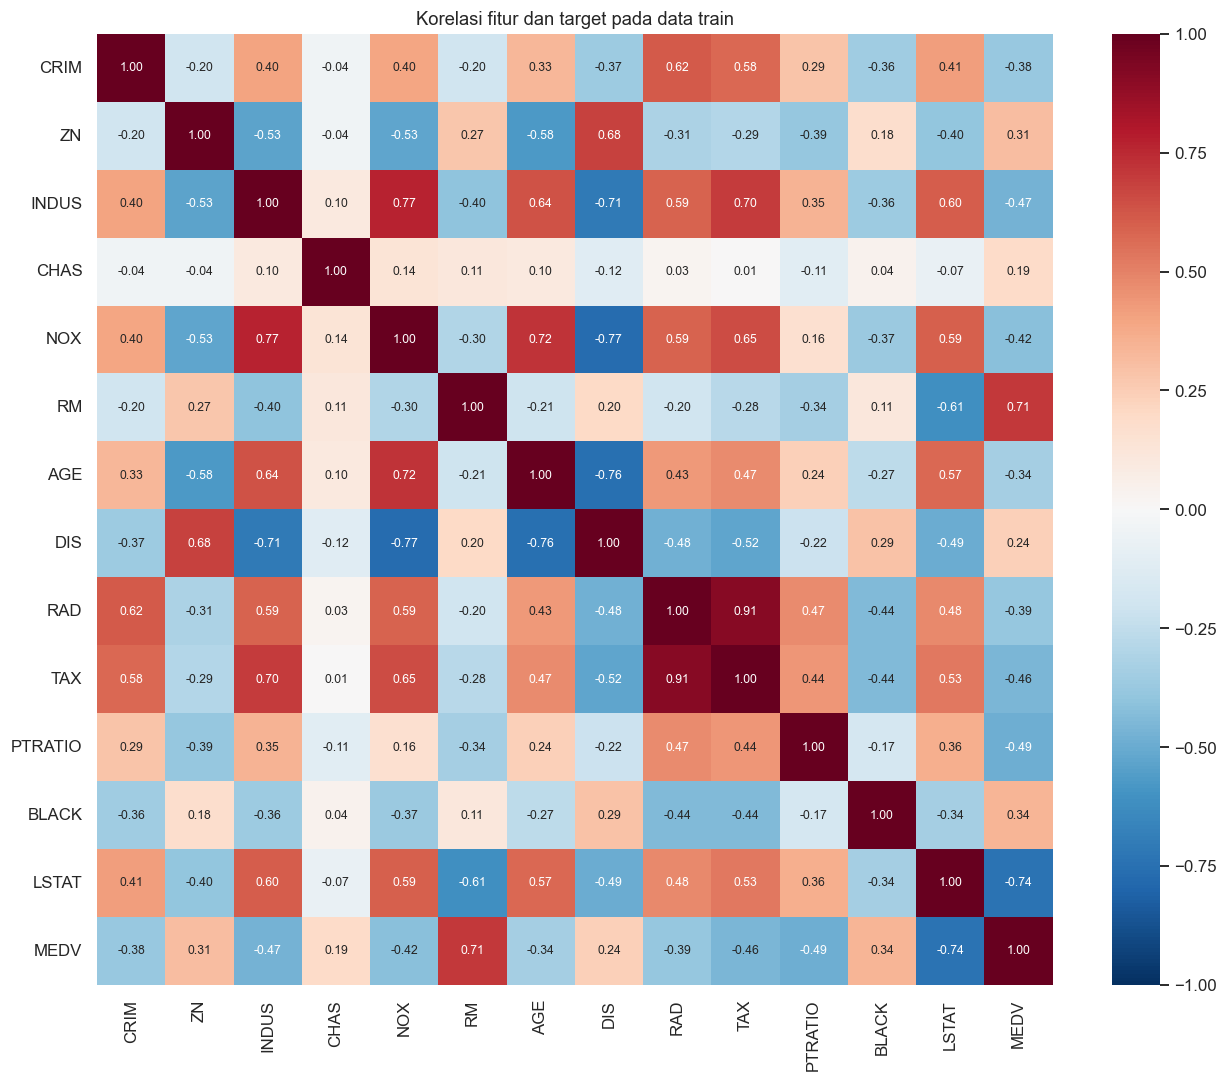

In [15]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    korelasi,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
)
plt.title("Korelasi fitur dan target pada data train")
plt.tight_layout()
plt.show()



TAX dan RAD berkorelasi kuat, sekitar 0,91. Hubungan TAX dengan MEDV pada
train lebih kuat secara absolut daripada RAD dengan MEDV. Korelasi ini tidak
menentukan sebab akibat dan tidak cukup sendirian untuk memilih semua fitur.

### 6.2 Hitung VIF tiap fitur

`add_constant()` menambahkan konstanta pada kolom posisi 0. Perhitungan di bawah
dimulai dari posisi 1 sampai 13 untuk fitur asli. Satu baris menghitung satu VIF;
barisnya sengaja ditulis lengkap agar tidak perlu mempelajari perulangan.



In [16]:
matriks_vif = add_constant(X_train_bersih)
tabel_vif = pd.DataFrame({"fitur": X_train_bersih.columns})
tabel_vif["VIF"] = [
    variance_inflation_factor(matriks_vif.values, 1),
    variance_inflation_factor(matriks_vif.values, 2),
    variance_inflation_factor(matriks_vif.values, 3),
    variance_inflation_factor(matriks_vif.values, 4),
    variance_inflation_factor(matriks_vif.values, 5),
    variance_inflation_factor(matriks_vif.values, 6),
    variance_inflation_factor(matriks_vif.values, 7),
    variance_inflation_factor(matriks_vif.values, 8),
    variance_inflation_factor(matriks_vif.values, 9),
    variance_inflation_factor(matriks_vif.values, 10),
    variance_inflation_factor(matriks_vif.values, 11),
    variance_inflation_factor(matriks_vif.values, 12),
    variance_inflation_factor(matriks_vif.values, 13),
]
tabel_vif.round(3)



,fitur,VIF
0,CRIM,1.713
1,ZN,2.466
2,INDUS,3.878
3,CHAS,1.097
4,NOX,4.469
5,RM,1.948
6,AGE,2.990
7,DIS,4.169
8,RAD,7.658
9,TAX,8.943


### 6.3 Contoh pengurangan fitur sesuai slide: keluarkan RAD

Untuk latihan ini kita membandingkan dua kandidat yang ditentukan sebelum membaca
hasil test: semua fitur, dan fitur tanpa RAD. Kita mempertahankan TAX seperti contoh
slide 25. Nama tabel baru menjaga data awal tetap tersedia. Penghapusan ini merupakan
pilihan ilustratif berdasarkan korelasi dan konteks; tidak menjamin RMSE membaik.



In [17]:
X_train_ringkas = X_train_bersih.drop(columns=["RAD"])
X_test_ringkas = X_test_bersih.drop(columns=["RAD"])
print("Fitur model lengkap:", X_train_bersih.shape[1])
print("Fitur model ringkas:", X_train_ringkas.shape[1])



Fitur model lengkap: 13
Fitur model ringkas: 12


In [18]:
matriks_vif = add_constant(X_train_ringkas)
vif_tanpa_rad = pd.DataFrame({"fitur": X_train_ringkas.columns})
vif_tanpa_rad["VIF"] = [
    variance_inflation_factor(matriks_vif.values, 1),
    variance_inflation_factor(matriks_vif.values, 2),
    variance_inflation_factor(matriks_vif.values, 3),
    variance_inflation_factor(matriks_vif.values, 4),
    variance_inflation_factor(matriks_vif.values, 5),
    variance_inflation_factor(matriks_vif.values, 6),
    variance_inflation_factor(matriks_vif.values, 7),
    variance_inflation_factor(matriks_vif.values, 8),
    variance_inflation_factor(matriks_vif.values, 9),
    variance_inflation_factor(matriks_vif.values, 10),
    variance_inflation_factor(matriks_vif.values, 11),
    variance_inflation_factor(matriks_vif.values, 12),
]
vif_tanpa_rad.round(3)



,fitur,VIF
0,CRIM,1.594
1,ZN,2.414
2,INDUS,3.658
3,CHAS,1.085
4,NOX,4.412
5,RM,1.885
6,AGE,2.977
7,DIS,4.166
8,TAX,3.331
9,PTRATIO,1.776


Bandingkan VIF TAX sebelum dan sesudah RAD dikeluarkan. Penurunannya menunjukkan
berkurangnya informasi berulang pada X. Kualitas prediksi tetap dinilai terpisah.



## 7. Latih regresi berganda

Model pertama memakai semua fitur. Model kedua memakai fitur tanpa RAD.
Keduanya dilatih pada observasi train yang sama. `LinearRegression()` membuat
wadah model, sedangkan `fit()` menghitung intersep dan koefisiennya.



In [19]:
model_berganda = LinearRegression()
model_berganda.fit(X_train_bersih, y_train)

model_ringkas = LinearRegression()
model_ringkas.fit(X_train_ringkas, y_train)

tabel_koefisien = pd.DataFrame(
    {"fitur": X_train_bersih.columns, "koefisien": model_berganda.coef_}
)
print("Intersep model berganda:", round(model_berganda.intercept_, 3))
tabel_koefisien.round(3)



Intersep model berganda: 30.247


,fitur,koefisien
0,CRIM,-0.113
1,ZN,0.030
2,INDUS,0.040
3,CHAS,2.784
4,NOX,-17.203
5,RM,4.439
6,AGE,-0.006
7,DIS,-1.448
8,RAD,0.262
9,TAX,-0.011


Setiap koefisien berganda adalah perubahan prediksi MEDV untuk satu unit fitur
tersebut **dengan fitur lain tetap**. Slope RM dapat berbeda dari model sederhana
karena variabel lain kini ikut diperhitungkan. Koefisien terbesar secara absolut
tidak otomatis menunjukkan fitur paling penting karena satuan fiturnya berbeda.
scikit-learn pada praktik ini dipakai untuk prediksi; tabel ini tidak memberikan p-value.



## 8. Buat prediksi pada data test

Model sudah ditentukan sebelum evaluasi test. Satu prediksi dibuat untuk setiap
baris test. Sebagai pembanding sederhana, `DummyRegressor` selalu memprediksi
rata-rata MEDV **dari train**. Model sebaiknya memberikan manfaat dibanding tebakan ini.



In [20]:
prediksi_sederhana = model_sederhana.predict(X_test_sederhana)
prediksi_berganda = model_berganda.predict(X_test_bersih)
prediksi_ringkas = model_ringkas.predict(X_test_ringkas)

model_pembanding = DummyRegressor(strategy="mean")
model_pembanding.fit(X_train_bersih, y_train)
prediksi_pembanding = model_pembanding.predict(X_test_bersih)

hasil_uji = pd.DataFrame(
    {"aktual": y_test, "prediksi": prediksi_berganda}, index=y_test.index
)
hasil_uji["error"] = hasil_uji["aktual"] - hasil_uji["prediksi"]
hasil_uji.head(10).round(3)



,aktual,prediksi,error
173,23.6,28.997,-5.397
274,32.4,36.026,-3.626
491,13.6,14.817,-1.217
72,22.8,25.032,-2.232
452,16.1,18.770,-2.670
76,20.0,23.254,-3.254
316,17.8,17.663,0.137
140,14.0,14.341,-0.341
471,19.6,23.013,-3.413
500,16.8,20.632,-3.832


## 9. Evaluasi: RMSE, R², dan grafik

**RMSE** adalah akar rata-rata kuadrat error. Satuannya sama dengan MEDV,
yaitu ribuan dolar AS. Semakin kecil, semakin dekat prediksi dengan aktual secara
keseluruhan. RMSE bukan jaminan bahwa setiap error berada dalam rentang ±RMSE
dan bukan otomatis interval prediksi atau standar deviasi residual.

**R²** membandingkan jumlah kuadrat error dengan variasi target pada sampel
yang dievaluasi: $R^2 = 1 - SSE/SST$. Nilai 1 adalah kecocokan sempurna, 0 setara
dengan patokan rata-rata target pada sampel evaluasi, dan **bisa negatif**.
R² bukan persentase prediksi yang benar atau ukuran sebab akibat.

Kita memakai `np.sqrt(mean_squared_error(...))` agar rumus RMSE terlihat jelas
dan tidak bergantung pada ketersediaan fungsi RMSE pada versi paket tertentu.



In [21]:
rmse_pembanding = np.sqrt(mean_squared_error(y_test, prediksi_pembanding))
rmse_sederhana = np.sqrt(mean_squared_error(y_test, prediksi_sederhana))
rmse_berganda = np.sqrt(mean_squared_error(y_test, prediksi_berganda))
rmse_ringkas = np.sqrt(mean_squared_error(y_test, prediksi_ringkas))

r2_pembanding = r2_score(y_test, prediksi_pembanding)
r2_sederhana = r2_score(y_test, prediksi_sederhana)
r2_berganda = r2_score(y_test, prediksi_berganda)
r2_ringkas = r2_score(y_test, prediksi_ringkas)

evaluasi = pd.DataFrame(
    {
        "model": [
            "Rata-rata train",
            "Sederhana: RM",
            "Berganda: 13 fitur",
            "Berganda: tanpa RAD",
        ],
        "RMSE_test": [rmse_pembanding, rmse_sederhana, rmse_berganda, rmse_ringkas],
        "R2_test": [r2_pembanding, r2_sederhana, r2_berganda, r2_ringkas],
    }
)
evaluasi.round(4)



,model,RMSE_test,R2_test
0,Rata-rata train,8.663,-0.023
1,Sederhana: RM,6.793,0.371
2,Berganda: 13 fitur,4.929,0.669
3,Berganda: tanpa RAD,5.145,0.639


Pada data dan pembagian yang disediakan, model semua fitur memberi RMSE sekitar
4,93 dan R² sekitar 0,669. Tanpa RAD, RMSE sekitar 5,14 dan R² sekitar 0,639.
Artinya, VIF yang lebih rendah **tidak otomatis memperbaiki prediksi**.
Untuk model lengkap, RMSE 4,93 setara skala error kuadratik sekitar US$4.930
dalam satuan data historis. Ini tidak menyatakan semua prediksi meleset sebesar itu.

Angka pada slide dapat berbeda karena contoh, data, dan pembagian observasinya
berbeda. Untuk berkas ini, gunakan output aktual. Tabel test melaporkan kandidat
yang sudah ditetapkan; jangan melanjutkan pencarian model dengan melihat test berulang.



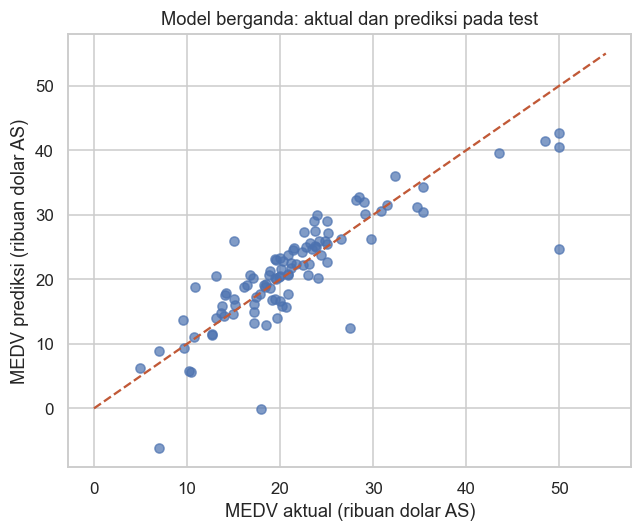

In [22]:
# Titik yang dekat dengan garis diagonal menunjukkan prediksi yang dekat aktual.
plt.figure(figsize=(6, 5))
plt.scatter(hasil_uji["aktual"], hasil_uji["prediksi"], alpha=0.7)
plt.plot([0, 55], [0, 55], linestyle="--", color="#C15937")
plt.xlabel("MEDV aktual (ribuan dolar AS)")
plt.ylabel("MEDV prediksi (ribuan dolar AS)")
plt.title("Model berganda: aktual dan prediksi pada test")
plt.tight_layout()
plt.show()



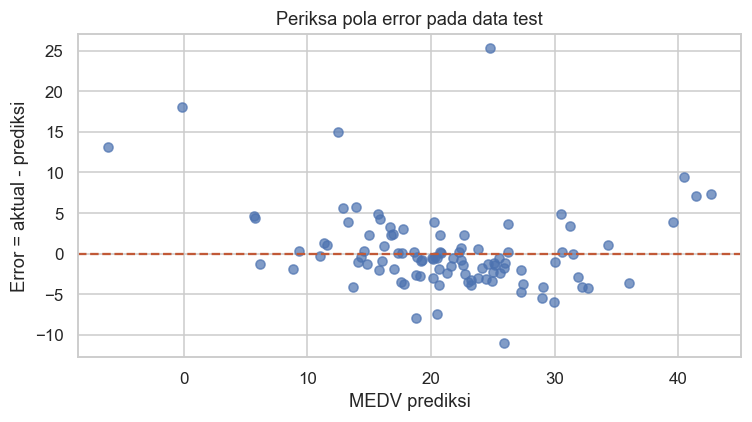

In [23]:
plt.figure(figsize=(7, 4))
plt.scatter(hasil_uji["prediksi"], hasil_uji["error"], alpha=0.7)
plt.axhline(0, linestyle="--", color="#C15937")
plt.xlabel("MEDV prediksi")
plt.ylabel("Error = aktual - prediksi")
plt.title("Periksa pola error pada data test")
plt.tight_layout()
plt.show()



Error positif berarti model memprediksi terlalu rendah; error negatif berarti
terlalu tinggi. Pola melengkung, sebaran melebar, dan titik ekstrem dapat menjadi
petunjuk keterbatasan model. Grafik ini bukan bukti bahwa semua asumsi sudah terpenuhi.



## 10. Prediksi dua profil baru

Tabel berikut adalah contoh profil wilayah, bukan observasi test atau harga rumah
tertentu. Setiap kolom bernama sama seperti fitur train. Satu nilai CRIM sengaja
dibuat kosong (`np.nan`) agar kita melihat imputer bekerja pada data baru.
Gunakan `transform()`, bukan `fit_transform()`, sehingga median train tetap dipakai.



In [24]:
data_baru = pd.DataFrame(
    {
        "CRIM": [np.nan, 0.2],
        "ZN": [18.0, 0.0],
        "INDUS": [5.0, 7.0],
        "CHAS": [0, 1],
        "NOX": [0.50, 0.55],
        "RM": [6.5, 7.0],
        "AGE": [50.0, 35.0],
        "DIS": [4.0, 3.0],
        "RAD": [4, 5],
        "TAX": [300.0, 350.0],
        "PTRATIO": [18.0, 17.0],
        "BLACK": [390.0, 380.0],
        "LSTAT": [8.0, 10.0],
    }
)

data_baru_bersih = pd.DataFrame(
    pengisi_kosong.transform(data_baru), columns=X_train.columns, index=data_baru.index
)
print("CRIM sebelum diisi:")
print(data_baru["CRIM"])
print("CRIM setelah memakai median train:")
print(data_baru_bersih["CRIM"])



CRIM sebelum diisi:
0    NaN
1    0.2
Name: CRIM, dtype: float64
CRIM setelah memakai median train:
0    0.261
1    0.200
Name: CRIM, dtype: float64


In [25]:
prediksi_baru = model_berganda.predict(data_baru_bersih)
hasil_baru = data_baru_bersih.copy()
hasil_baru["prediksi_MEDV"] = prediksi_baru
hasil_baru[["RM", "LSTAT", "prediksi_MEDV"]].round(3)



,RM,LSTAT,prediksi_MEDV
0,6.5,8.0,27.232
1,7.0,10.0,31.968


## 11. Pengayaan: merangkai langkah dengan Pipeline

Kita sudah melakukan dua langkah: mengisi nilai kosong dan menjalankan regresi.
`make_pipeline()` merangkainya dengan urutan yang sama. Saat `fit()` dipanggil,
median dan regresi dipelajari dari train. Saat `predict()`, transformasi train dipakai
otomatis pada data yang diberikan. Jadi masukan pipeline adalah **fitur mentah**.

Nama langkah tidak perlu ditulis sendiri pada contoh ini. Bagi pemula, pahami
versi manual lebih dahulu, kemudian cocokkan hasil pipeline di bawah.



In [26]:
from sklearn.pipeline import make_pipeline

model_otomatis = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
model_otomatis.fit(X_train, y_train)

prediksi_otomatis = model_otomatis.predict(X_test)
print(
    "Prediksi pipeline sama dengan versi manual:",
    np.allclose(prediksi_otomatis, prediksi_berganda),
)
print("Prediksi profil baru dari data mentah:", model_otomatis.predict(data_baru))



Prediksi pipeline sama dengan versi manual: True
Prediksi profil baru dari data mentah: [27.23184366 31.96848265]


## 12. Pengayaan: underfitting dan overfitting

**Underfitting:** model terlalu sederhana untuk menangkap pola; error train dan
validasi sama-sama besar. **Overfitting:** model mengikuti detail/noise train;
hasil train membaik tetapi tidak diikuti perbaikan pada data yang belum dipelajari.

Untuk memperagakan ini, kita memakai **RM saja**, lalu mengambil train kecil dan
validasi **dari data train awal**. Data test 102 baris tidak dipakai untuk memilih
derajat polinomial. Perbandingan ini mempunyai tujuan berbeda dari model 13 fitur.

Empat kandidat: tebakan konstan, garis lurus, kuadratik, dan polinomial derajat 10.
Pangkat tinggi bukan otomatis lebih baik. StandardScaler mengubah skala RM sebelum
pangkat dibuat agar perhitungan lebih stabil; semua parameter dipelajari dari train kecil.



In [27]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

RM_latih, RM_validasi, harga_latih, harga_validasi = train_test_split(
    X_train[["RM"]], y_train, test_size=0.25, random_state=42
)

model_konstan = make_pipeline(
    SimpleImputer(strategy="median"), DummyRegressor(strategy="mean")
)
model_lurus = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
model_kuadrat = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression(),
)
model_lentur = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PolynomialFeatures(degree=10, include_bias=False),
    LinearRegression(),
)

model_konstan.fit(RM_latih, harga_latih)
model_lurus.fit(RM_latih, harga_latih)
model_kuadrat.fit(RM_latih, harga_latih)
model_lentur.fit(RM_latih, harga_latih)
print("Train kecil:", len(RM_latih), "Validasi:", len(RM_validasi))



Train kecil: 303 Validasi: 101


In [28]:
rmse_train_konstan = np.sqrt(
    mean_squared_error(harga_latih, model_konstan.predict(RM_latih))
)
rmse_train_lurus = np.sqrt(
    mean_squared_error(harga_latih, model_lurus.predict(RM_latih))
)
rmse_train_kuadrat = np.sqrt(
    mean_squared_error(harga_latih, model_kuadrat.predict(RM_latih))
)
rmse_train_lentur = np.sqrt(
    mean_squared_error(harga_latih, model_lentur.predict(RM_latih))
)

rmse_validasi_konstan = np.sqrt(
    mean_squared_error(harga_validasi, model_konstan.predict(RM_validasi))
)
rmse_validasi_lurus = np.sqrt(
    mean_squared_error(harga_validasi, model_lurus.predict(RM_validasi))
)
rmse_validasi_kuadrat = np.sqrt(
    mean_squared_error(harga_validasi, model_kuadrat.predict(RM_validasi))
)
rmse_validasi_lentur = np.sqrt(
    mean_squared_error(harga_validasi, model_lentur.predict(RM_validasi))
)

perbandingan_kompleksitas = pd.DataFrame(
    {
        "model": ["Konstan", "Linear", "Polinomial 2", "Polinomial 10"],
        "RMSE_train": [
            rmse_train_konstan,
            rmse_train_lurus,
            rmse_train_kuadrat,
            rmse_train_lentur,
        ],
        "RMSE_validasi": [
            rmse_validasi_konstan,
            rmse_validasi_lurus,
            rmse_validasi_kuadrat,
            rmse_validasi_lentur,
        ],
    }
)
perbandingan_kompleksitas.round(3)



,model,RMSE_train,RMSE_validasi
0,Konstan,9.469,8.860
1,Linear,6.564,6.538
2,Polinomial 2,6.235,6.251
3,Polinomial 10,5.680,6.449


Pada pembagian ini, polinomial 10 memperbaiki RMSE train dibanding kuadratik,
tetapi RMSE validasinya memburuk. Itu tanda model lebih lentur mulai mengikuti
detail train tanpa tambahan manfaat pada validasi. Model konstan menunjukkan
keterbatasan model yang tidak memakai pola RM sama sekali. Kesimpulan ini
bergantung sampel; derajat tinggi tidak selalu overfit pada setiap dataset.



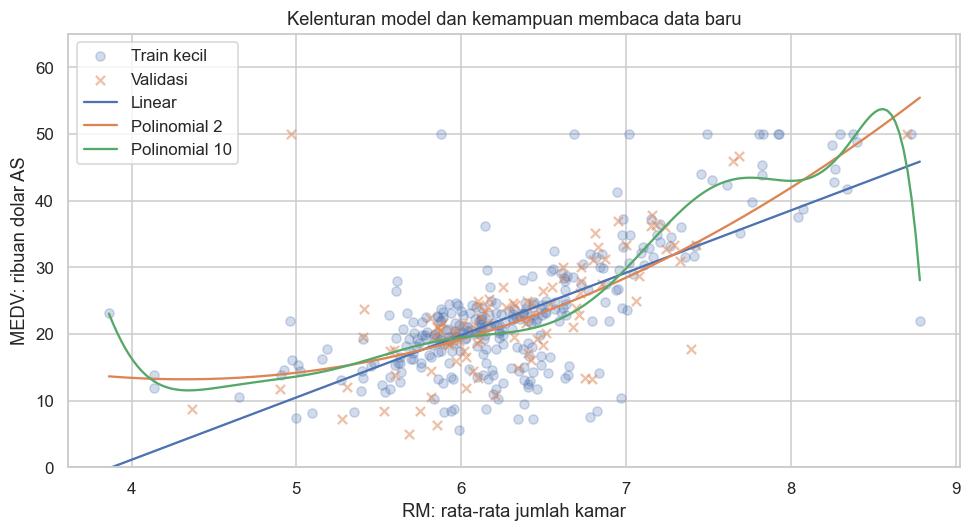

In [29]:
kurva = pd.DataFrame(
    {"RM": np.linspace(RM_latih["RM"].min(), RM_latih["RM"].max(), 200)}
)

plt.figure(figsize=(9, 5))
plt.scatter(RM_latih["RM"], harga_latih, alpha=0.25, label="Train kecil")
plt.scatter(RM_validasi["RM"], harga_validasi, alpha=0.5, marker="x", label="Validasi")
plt.plot(kurva["RM"], model_lurus.predict(kurva), label="Linear")
plt.plot(kurva["RM"], model_kuadrat.predict(kurva), label="Polinomial 2")
plt.plot(kurva["RM"], model_lentur.predict(kurva), label="Polinomial 10")
plt.xlabel("RM: rata-rata jumlah kamar")
plt.ylabel("MEDV: ribuan dolar AS")
plt.title("Kelenturan model dan kemampuan membaca data baru")
plt.ylim(0, 65)
plt.legend()
plt.tight_layout()
plt.show()



## 13. Latihan dan ringkasan

1. Dari persamaan regresi sederhana, berapa perubahan prediksi saat RM naik
   dari 6 ke 7? Bandingkan dengan tabel `contoh_rm`.
2. Jelaskan mengapa `fit_transform()` hanya dijalankan pada train.
3. Bandingkan VIF TAX pada `tabel_vif` dan `vif_tanpa_rad`. Apakah RMSE test
   pasti ikut membaik ketika VIF turun?
4. Pada `data_baru`, ubah RM profil pertama dari 6,5 menjadi 7,5, kemudian
   jalankan ulang transformasi dan prediksinya. Fitur lain tetap. Bandingkan
   perubahan prediksi dengan koefisien RM pada model berganda.
5. Mengapa R² = 0,669 tidak berarti 66,9% prediksi tepat?

<details><summary>Petunjuk jawaban</summary>

1. Selisih kedua prediksi sederhana sama dengan slope RM karena selisih RM satu unit.
2. Median test/new data harus berasal dari train agar proses belajar tidak memakai
   informasi data evaluasi.
3. VIF TAX turun setelah RAD dikeluarkan, tetapi pada berkas ini RMSE test model
   ringkas justru lebih besar. Tujuan interpretasi dan tujuan prediksi perlu dibedakan.
4. Dengan perbedaan RM satu unit dan fitur lain tetap, selisih prediksi sama dengan
   koefisien RM model berganda. Hasil imputer harus tetap berasal dari train yang sama.
5. R² mengukur perbandingan kuadrat error terhadap variasi target, bukan menghitung
   proporsi prediksi yang dianggap tepat.

</details>

Tuliskan kesimpulan dengan pola: **data apa**, **model apa**, **hasil test**,
**satuan**, dan **keterbatasan**. Contoh: pada pembagian 80:20 housing.csv,
regresi 13 fitur menghasilkan RMSE test sekitar 4,93 ribu dolar AS historis dan
R² sekitar 0,669. Hasil ini untuk latihan pada sampel tersebut, belum menjadi
bukti kausal atau jaminan kinerja pada wilayah dan tahun lain.

### Jika muncul error

| Pesan | Yang diperiksa |
|---|---|
| FileNotFoundError | Jalankan sel persiapan; di Colab unggah housing.csv atau data_tutorial.zip. |
| NameError | Jalankan sel sebelumnya dari atas; periksa nama variabel. |
| KeyError | Cocokkan nama kolom dengan `print(data.columns)`. |
| ModuleNotFoundError | Pada komputer lokal, pasang paket dari requirements.txt sebelum membuka notebook. |
| ValueError tentang fitur/NaN | Pastikan daftar kolom sama; gunakan imputer yang sudah dilatih. |

### Rujukan

- Gambar slide: **slide/png_regresi_tajam/**, terutama halaman 17-30 (6000 × 3375 piksel).
- [Definisi variabel Boston Housing, Carnegie Mellon](https://lib.stat.cmu.edu/datasets/boston).
- [Catatan dataset Boston Housing, scikit-learn](https://scikit-learn.org/1.1/modules/generated/sklearn.datasets.load_boston.html).
- [Pencegahan data leakage, scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).
- [Definisi R², scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html).
- [Definisi VIF, statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).
